## Sentiment Classifier Using GRU

## Project Overview

This project implements a sentiment classification model using a many-to-one GRU architecture in PyTorch. Trained on the Yelp dataset with pre-trained GloVe word embeddings, it classifies customer reviews into ratings ranging from 1 to 5 stars.

## Architecture and Methodology

<b>1) Word Embeddings:</b> Uses pre-trained GloVe embeddings to represent textual input as numerical vectors.

<b>2) GRU Network:</b> Processes sequential text data using a many-to-one GRU architecture to capture contextual information.

<b>3) Classification:</b> Predicts one of five sentiment classes corresponding to 1–5 star ratings.

<b>4) Gradio Interface:</b> Provides an interactive interface for users to enter reviews and obtain predicted ratings.

## Key Feature

Performs multi-class sentiment classification of customer reviews and provides predictions through an interactive Gradio interface.

In [1]:
import re, json, random, time
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_sequence
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset
import gensim.downloader as api
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', device)

torch 2.14.1+cpu | device: cpu


In [2]:
N_TRAIN = 20000
N_TEST = 5000
MAX_VOCAB = 20000
MAX_LEN = 200
EMB_DIM = 300
HIDDEN = 128
BATCH = 64
EPOCHS = 1
LR = 1e-3

In [3]:
try:
    raw = load_dataset('Yelp/yelp_review_full')
except Exception:
    raw = load_dataset('yelp_review-full')
print(raw)

DatasetDict({
    train: Dataset({
        features: ['label', 'text'],
        num_rows: 650000
    })
    test: Dataset({
        features: ['label', 'text'],
        num_rows: 50000
    })
})


In [4]:
import os
os.environ['HF_HUB_DISABLE_XET'] = '1'
os.environ['HF_HUB_DOWNLOAD_TIMEOUT'] = '60'

In [5]:
full_train = raw['train'].shuffle(seed=SEED).select(range(N_TRAIN))
test_ds = raw['test'].shuffle(seed=SEED).select(range(N_TEST))

split = full_train.train_test_split(test_size=0.1, seed=SEED)
train_ds, val_ds = split['train'], split['test']
print(len(train_ds), len(val_ds), len(test_ds))

18000 2000 5000


In [6]:
for i in range(3):
    print(train_ds[i]['label'] + 1, 'stars |', train_ds[i]['text'][:150])
print(sorted(Counter(train_ds['label']).items()))

2 stars | A Thanksgiving \"dont\".  A total turkey.   We were looking forward to a nice meal with our adult children and grandchild.  We were offered a selectio
5 stars | We went out of our way to visit Fuego Tacos, since I bought a deal off of Groupon, and we were blown away. If you want to compare the pricing to Filib
2 stars | I heard about this place for years and finally got chance to try, well, very disappointed. The snow crab legs are over-cooked and tasteless. The lobst
[(0, 3587), (1, 3618), (2, 3511), (3, 3617), (4, 3667)]


In [7]:
def tokenize(text):
    text = text.lower().replace(chr(92) + 'n', '')
    text = re.sub(r"n't(?![a-z])", lambda m: '' + m.group(0), text)
    text = re.sub(r"'(s|re|ve|ll|d|m)(?![a-z])", lambda m: '' + m.group(0), text)
    return re.findall(r"n't|'[a-z]+|[a-z0-9]+|[!?]", text)

print(tokenize("Don't waste your time!! The dentist wasn't rude."))

['don', "'t", 'waste', 'your', 'time', '!', '!', 'the', 'dentist', 'wasn', "'t", 'rude']


In [8]:
train_tokens = [tokenize(t) for t in train_ds['text']]
val_tokens = [tokenize(t) for t in val_ds['text']]
test_tokens = [tokenize(t) for t in test_ds['text']]

lengths = [len(t) for t in train_tokens]
print('avergae length:', np.mean(lengths), '| 90th percentile:', np.percentile(lengths, 90))

avergae length: 139.12766666666667 | 90th percentile: 292.0


In [9]:
counter = Counter(tok for toks in train_tokens for tok in toks)
word2idx = {'<PAD>': 0, '<UNK>': 1}
for word, _ in counter.most_common(MAX_VOCAB - 2):
    word2idx[word] = len(word2idx)
print('vocab size:', len(word2idx))
print(list(word2idx)[:12])

vocab size: 20000
['<PAD>', '<UNK>', 'the', 'and', 'i', 'a', 'to', 'was', 'it', 'of', 'for', 'in']


In [10]:
glove = api.load('glove-wiki-gigaword-300')
print(glove['excellent'].shape)
print(glove.most_similar('excellent', topn=5))

(300,)
[('good', 0.7039496302604675), ('superb', 0.6809257864952087), ('terrific', 0.6564303636550903), ('quality', 0.6036279797554016), ('wonderful', 0.5842511653900146)]


In [11]:
emb_matrix = np.random.normal(0, 0.1, (len(word2idx), EMB_DIM)).astype('float32')
emb_matrix[0] = 0
found = 0
for word, i in word2idx.items():
    if word in glove:
        emb_matrix[i] = glove[word]
        found += 1
print(f'GloVe coverage: {found}/{len(word2idx)} = {found/len(word2idx):.1%}')
print('some missing words:', [w for w in list(word2idx)[2:400] if w not in glove][:15])
print(emb_matrix.shape)

GloVe coverage: 18641/20000 = 93.2%
some missing words: ["'t"]
(20000, 300)


In [12]:
def encode(tokens):
    ids = [word2idx.get(t,1) for t in tokens[:MAX_LEN]]
    return ids if ids else [1]

class ReviewDataset(Dataset):
    def __init__(self, token_lists, labels):
        self.ids = [encode(t) for t in token_lists]
        self.labels = list(labels)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        return self.ids[i], self.labels[i]
def collate(batch):
    seqs, labels = zip(*batch)
    lengths = torch.tensor([len(s) for s in seqs])
    padded = pad_sequence([torch.tensor(s) for s in seqs], batch_first=True, padding_value=0)
    return padded, lengths, torch.tensor(labels)

In [13]:
train_loader = DataLoader(ReviewDataset(train_tokens, train_ds['label']), batch_size=BATCH, shuffle=True, collate_fn=collate)
val_loader = DataLoader(ReviewDataset(val_tokens, val_ds['label']), batch_size=BATCH, shuffle=False, collate_fn=collate)
test_loader = DataLoader(ReviewDataset(test_tokens, test_ds['label']), batch_size=BATCH, shuffle=False, collate_fn=collate)

x, lengths, y = next(iter(train_loader))
print(x.shape, lengths[:8], y[:8])

torch.Size([64, 200]) tensor([ 81,  68,  64, 200,  63,  88,  38,  43]) tensor([2, 3, 1, 0, 2, 1, 0, 4])


In [14]:
class SentimentGRU(nn.Module):
    def __init__(self, emb_matrix, hidden=128, n_classes=5, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=True, padding_idx=0)
        self.gru = nn.GRU(emb_matrix.shape[1], hidden, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden, n_classes)

    def forward(self, x, lengths):
        e = self.emb(x)
        packed = pack_padded_sequence(e, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, h = self.gru(packed)
        return self.fc(self.drop(h[-1]))

In [15]:
model = SentimentGRU(emb_matrix, hidden=HIDDEN).to(device)
print(model)
print('trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))

SentimentGRU(
  (emb): Embedding(20000, 300, padding_idx=0)
  (gru): GRU(300, 128, batch_first=True)
  (drop): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=5, bias=True)
)
trainable parameters: 165765


In [16]:
loss_fn = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    tot_loss = correct = within1 = n = 0
    with torch.set_grad_enabled(training):
        for x, lengths, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x, lengths)
            loss = loss_fn(logits, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            preds = logits.argmax(dim=1)
            tot_loss += loss.item() * len(y)
            correct += (preds == y).sum().item()
            within1 += ((preds - y).abs() <= 1).sum().item()
            n += len(y)
    return tot_loss / n, correct / n, within1 / n

def train_model(model, epochs, lr, save_path):
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(params, lr=lr)
    hist = {'tr_loss' : [], 'va_loss':[], 'tr_acc': [], 'va_acc': []}
    best = 0.0
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc, _ = run_epoch(model, train_loader, optimizer)
        va_loss, va_acc, va_w1 = run_epoch(model, val_loader)
        hist['tr_loss'].append(tr_loss); hist['va_loss'].append(va_loss)
        hist['tr_acc'].append(tr_acc); hist['va_acc'].append(va_acc)
        print(f'epoch {ep:2d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | val loss {va_loss:.3f} acc {va_acc:.3f} within-1 {va_w1:.3f} | {time.time()-t0:.0f}s')
        if va_acc > best:
            best = va_acc
            torch.save(model.state_dict(), save_path)
    print('best validation accuracy:', round(best,3))
    return hist
                

In [17]:
history = train_model(model, EPOCHS, LR, 'best_gru.pt')

epoch  1 | train loss 1.379 acc 0.380 | val loss 1.195 acc 0.494 within-1 0.866 | 536s
best validation accuracy: 0.494


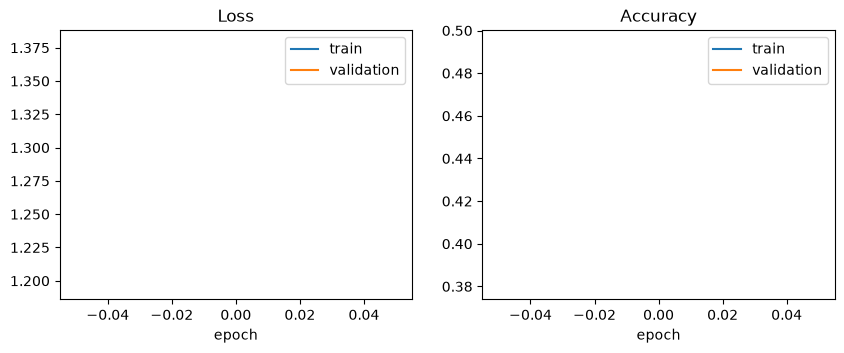

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history['tr_loss'], label='train'); ax[0].plot(history['va_loss'], label='validation')
ax[0].set_title('Loss'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(history['tr_acc'], label='train'); ax[1].plot(history['va_acc'], label='validation')
ax[1].set_title('Accuracy'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.show()

In [19]:
model.load_state_dict(torch.load('best_gru.pt', map_location=device))

def get_preds(model, loader):
    model.eval()
    ps, ys = [], []
    with torch.no_grad():
        for x, lengths, y in loader:
            ps.append(model(x.to(device), lengths).argmax(1).cpu())
            ys.append(y)
    return torch.cat(ps).numpy(), torch.cat(ys).numpy()

preds, ys = get_preds(model, test_loader)
print('exact accuracy:', (preds == ys).mean())
print('within 1 star:', (np.abs(preds-ys) <= 1).mean())
print('\ncondusion matrix (rows = true 1..5 stars, columns = predicted):')
print(confusion_matrix(ys, preds))
print(classification_report(ys, preds, target_names=['1', '2', '3', '4', '5']))

exact accuracy: 0.475
within 1 star: 0.8496

condusion matrix (rows = true 1..5 stars, columns = predicted):
[[805  65  68  30  64]
 [440 140 208 129  69]
 [142  66 270 374 122]
 [ 41  18 101 627 268]
 [ 38   4  27 351 533]]
              precision    recall  f1-score   support

           1       0.55      0.78      0.64      1032
           2       0.48      0.14      0.22       986
           3       0.40      0.28      0.33       974
           4       0.41      0.59      0.49      1055
           5       0.50      0.56      0.53       953

    accuracy                           0.47      5000
   macro avg       0.47      0.47      0.44      5000
weighted avg       0.47      0.47      0.44      5000



In [20]:
def predict(text):
    model.eval()
    ids = encode(tokenize(text))
    x = torch.tensor([ids]).to(device)
    lengths = torch.tensor([len(ids)])
    with torch.no_grad():
        probs = torch.softmax(model(x, lengths), dim=1)[0].cpu()
    return int(probs.argmax()) + 1, probs

tests = [
    'The dessert is excellent',
    'Service was quite slow',
    'Good for a quick meal, but nothing special',
    'completely lacking in good taste, good service and good ambience', 
    'Courier left my pracel in the rain and never replied to my complaint.',
    'Rude staff.',
]
for t in tests:
    stars, probs = predict(t)
    print(stars, 'stars', [f'{p:.2f}' for p in probs.tolist()], '|', t)

4 stars ['0.02', '0.07', '0.19', '0.40', '0.33'] | The dessert is excellent
3 stars ['0.18', '0.23', '0.29', '0.18', '0.11'] | Service was quite slow
3 stars ['0.06', '0.12', '0.30', '0.30', '0.22'] | Good for a quick meal, but nothing special
2 stars ['0.12', '0.30', '0.28', '0.17', '0.12'] | completely lacking in good taste, good service and good ambience
1 stars ['0.55', '0.21', '0.08', '0.05', '0.11'] | Courier left my pracel in the rain and never replied to my complaint.
1 stars ['0.48', '0.25', '0.11', '0.07', '0.09'] | Rude staff.


In [21]:
with open('word2idx.json', 'w') as f:
    json.dump(word2idx, f)
print('saved best_gru.pt and word2idx.json')

saved best_gru.pt and word2idx.json


In [22]:
word2idx =  json.load(open('word2idx.json'))
model = SentimentGRU(np.zeros((len(word2idx), 300), dtype='float32')).to(device)
model.load_state_dict(torch.load('best_gru.pt', map_location=device))

<All keys matched successfully>

In [23]:
stars, probs=predict('The plumber arrived late but fixed everything quickly and cleaned up.')
print(stars, 'stars')
print([f'{p:.2f}' for p in probs.tolist()])

1 stars
['0.25', '0.24', '0.18', '0.14', '0.19']


In [24]:
import gradio as gr 
def rate(text):
    if not text.strip():
        return 'Please type a review.', {}
    stars, probs = predict(text)
    label = '⭐' * stars + f'  ({stars}/5)'
    return label, {f'{i+1} star': float(probs[i]) for i in range(5)}
demo = gr.Interface(
    fn=rate,
    inputs=gr.Textbox(lines=4, label='Type your review'),
    outputs=[gr.Textbox(label='Predicted rating'),
             gr.Label(label='Probability of each rating', num_top_classes=5)],
    title='Review Star Rating',
)
demo.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [25]:
demo.close() #to stop running gradio interface

Closing server running on port: 7860
